In [1]:
import os

os.environ["EXTRA_CLING_ARGS"] = "-Wno-nonportable-include-path"

from ogdf_python import cppinclude, ogdf

from qelebrimbor.formats.ogdf import OGDF
from qelebrimbor.formats.pyzx import PYZX

cppinclude("ogdf/planarity/PlanarizationLayout.h")
cppinclude("ogdf/orthogonal/OrthoLayout.h")
cppinclude("ogdf/orthogonal/FlowCompaction.h")
cppinclude("ogdf/planarity/EmbedderMinDepthMaxFaceLayers.h")

True

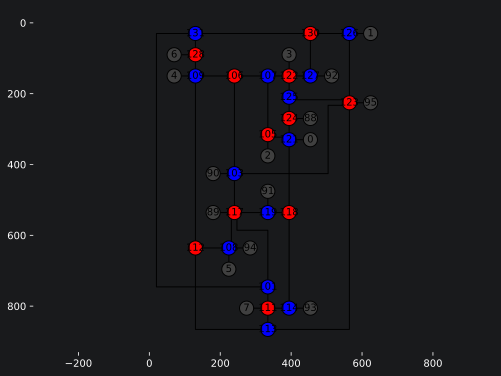

In [2]:
# Convert graph from VZX to OGDF for running layout algorithm
ogg, attributes = OGDF.from_pyzx_graph(
    PYZX.from_file("../benchmarking/datasets/medio/identity/quick/random-cnots-q8-d32-s3746021966.pyzx.internal.json")
)

algorithm = ogdf.PlanarizationLayout()
layout = ogdf.OrthoLayout()
layout.__python_owns__ = False  # Needed to avoid C++ segmentation fault when object is destroyed
layout.separation(40)
algorithm.setPlanarLayouter(layout)

algorithm.call(attributes)

attributes

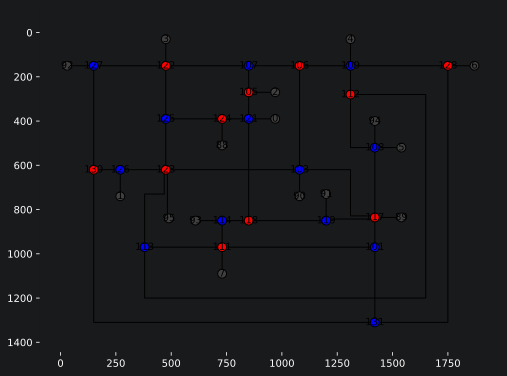

In [5]:
# Convert graph from VZX to OGDF for running layout algorithm
ogg, attributes = OGDF.from_pyzx_graph(
    PYZX.from_file("../benchmarking/datasets/medio/identity/quick/random-cnots-q8-d32-s3746021966.pyzx.internal.json")
)

algorithm = ogdf.PlanarizationLayout()
layout = ogdf.OrthoLayout()
layout.__python_owns__ = False  # Needed to avoid C++ segmentation fault when object is destroyed
layout.separation(100)
embedder = ogdf.EmbedderMinDepthMaxFaceLayers()
embedder.__python_owns__ = False
algorithm.setEmbedder(embedder)
algorithm.setPlanarLayouter(layout)

algorithm.call(attributes)

attributes